In [19]:
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder
import pandas as pd
import loguru as logging
from matplotlib import pyplot as plt
from PIL import Image

In [3]:
mapping = pd.read_csv(r"D:\galaxy classification\data\raw\mapping.csv")
labels = pd.read_csv(r"D:\galaxy classification\data\raw\labels.csv")

In [10]:
merge = pd.merge(mapping, labels, left_on='objid', right_on='dr7objid')
merge.head()

,objid,sample_x,asset_id,dr7objid,ra,dec,rastring,decstring,sample_y,gz2_class,...,t11_arms_number_a36_more_than_4_fraction,t11_arms_number_a36_more_than_4_weighted_fraction,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a36_more_than_4_flag,t11_arms_number_a37_cant_tell_count,t11_arms_number_a37_cant_tell_weight,t11_arms_number_a37_cant_tell_fraction,t11_arms_number_a37_cant_tell_weighted_fraction,t11_arms_number_a37_cant_tell_debiased,t11_arms_number_a37_cant_tell_flag
0,587722981741363294,original,3,587722981741363294,182.925262,-1.092357,12:11:42.06,-01:05:32.5,original,Sb,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
1,587722981741363323,original,4,587722981741363323,182.970108,-1.219537,12:11:52.83,-01:13:10.3,original,Sc?l,...,0.0,0.0,0.0,0,1,1.0,1.0,1.0,1.0,1
2,587722981741559888,original,5,587722981741559888,183.438095,-1.238414,12:13:45.14,-01:14:18.3,original,Er,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
3,587722981741625481,original,6,587722981741625481,183.473999,-1.231429,12:13:53.76,-01:13:53.1,original,Sc1t,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
4,587722981741625484,original,7,587722981741625484,183.477783,-1.084604,12:13:54.67,-01:05:04.6,original,Sb,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0


In [22]:
dir = r"D:\galaxy classification\images"

def load_image(id):
    img_path = f"{dir}/{id}.jpg"
    img = Image.open(img_path).convert('RGB')
    return img


In [48]:
debiased_df = merge[["objid","asset_id","sample_x","total_votes"]+[col for col in merge.columns if col.endswith('_debiased')]]


In [49]:
debiased_df

,objid,asset_id,sample_x,total_votes,t01_smooth_or_features_a01_smooth_debiased,t01_smooth_or_features_a02_features_or_disk_debiased,t01_smooth_or_features_a03_star_or_artifact_debiased,t02_edgeon_a04_yes_debiased,t02_edgeon_a05_no_debiased,t03_bar_a06_bar_debiased,...,t09_bulge_shape_a27_no_bulge_debiased,t10_arms_winding_a28_tight_debiased,t10_arms_winding_a29_medium_debiased,t10_arms_winding_a30_loose_debiased,t11_arms_number_a31_1_debiased,t11_arms_number_a32_2_debiased,t11_arms_number_a33_3_debiased,t11_arms_number_a34_4_debiased,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a37_cant_tell_debiased
0,587722981741363294,3,original,181,0.459,0.681,0.000,0.041914,0.914402,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
1,587722981741363323,4,original,111,0.216,0.736,0.000,0.000000,1.000000,0.376434,...,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000
2,587722981741559888,5,original,153,0.773,0.029,0.114,0.000000,1.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
3,587722981741625481,6,original,136,0.152,0.639,0.009,0.000000,1.000000,0.000000,...,0.00000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000
4,587722981741625484,7,original,150,0.182,0.720,0.032,0.000000,1.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239690,588015510368681992,295294,stripe82,273,0.000,1.000,0.000,0.000000,1.000000,0.912724,...,0.00000,0.395750,0.516223,0.080662,0.000000,0.068418,0.058680,0.50517,0.419035,0.029496
239691,588015510368682105,295295,stripe82,149,0.800,0.146,0.073,0.126668,0.836558,0.000000,...,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000
239692,588015510368682132,295296,stripe82,138,0.733,0.190,0.022,0.861468,0.232142,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
239693,588015510636265643,295304,stripe82,213,0.089,0.892,0.010,0.343208,0.668841,0.228637,...,0.58578,0.313458,0.266263,0.361677,0.075168,0.115436,0.000000,0.00000,0.000000,0.692101


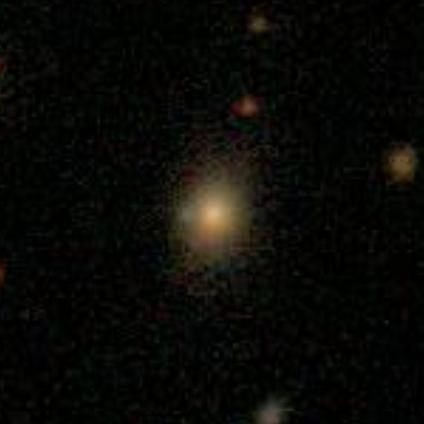

In [ ]:
img = load_image(3)
display(img)